In [89]:
import pymysql 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [90]:
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="12345",
    database="bank",
    port=3306
)

cur=conn.cursor()

In [91]:
query = "select * from clinet"



In [92]:
df=pd.read_sql_query(query,conn)


C:\Users\megha\AppData\Local\Temp\ipykernel_5316\851161782.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql_query(query,conn)


In [93]:
df.head()

,Client ID,Name,Age,Location ID,Joined Bank,Banking Contact,Nationality,Occupation,Fee Structure,Loyalty Classification,...,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,Gender,Investment Advisor,Banking Relationship
0,IND81288,Raymond Mills,24,34324,2019-05-06,Anthony Torres,American,Safety Technician IV,High,Jade,...,1.485829e+06,6.036179e+05,607332.455240,12249.9584,1.134475e+06,1,2,Male,Victor Dean,Retail
1,IND65833,Julia Spencer,23,42205,2001-12-10,Jonathan Hawkins,African,Software Consultant,High,Jade,...,6.414828e+05,2.295214e+05,344635.157402,61162.3089,2.000526e+06,1,3,Male,Jeremy Porter,Institutional
2,IND47499,Stephen Murray,27,7314,2010-01-25,Anthony Berry,European,Help Desk Operator,High,Gold,...,1.033402e+06,6.526747e+05,203054.348179,79071.7794,5.481376e+05,1,3,Female,Ernest Knight,Private Bank
3,IND72498,Virginia Garza,40,34594,2019-03-28,Steve Diaz,American,Geologist II,Mid,Silver,...,1.048157e+06,1.048157e+06,234685.019326,57513.6520,1.148402e+06,0,4,Male,Eric Shaw,Commercial
4,IND60181,Melissa Sanders,46,41269,2012-07-20,Shawn Long,American,Assistant Professor,Mid,Platinum,...,4.877825e+05,4.466442e+05,128351.452320,30012.1360,1.674412e+06,0,3,Female,Kevin Kim,Retail


In [94]:
df.isnull().sum()

Client ID                   0
Name                        0
Age                         0
Location ID                 0
Joined Bank                 0
Banking Contact             0
Nationality                 0
Occupation                  0
Fee Structure               0
Loyalty Classification      0
Estimated Income            0
Superannuation Savings      0
Amount of Credit Cards      0
Credit Card Balance         0
Bank Loans                  0
Bank Deposits               0
Checking Accounts           0
Saving Accounts             0
Foreign Currency Account    0
Business Lending            0
Properties Owned            0
Risk Weighting              0
Gender                      0
Investment Advisor          0
Banking Relationship        0
dtype: int64

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Client ID                 3000 non-null   object 
 1   Name                      3000 non-null   object 
 2   Age                       3000 non-null   int64  
 3   Location ID               3000 non-null   int64  
 4   Joined Bank               3000 non-null   object 
 5   Banking Contact           3000 non-null   object 
 6   Nationality               3000 non-null   object 
 7   Occupation                3000 non-null   object 
 8   Fee Structure             3000 non-null   object 
 9   Loyalty Classification    3000 non-null   object 
 10  Estimated Income          3000 non-null   float64
 11  Superannuation Savings    3000 non-null   float64
 12  Amount of Credit Cards    3000 non-null   int64  
 13  Credit Card Balance       3000 non-null   float64
 14  Bank Loa

In [96]:
# date convert 

In [97]:
df["Joined Bank"]=pd.to_datetime(df["Joined Bank"])

In [98]:
df["Bank Deposits"]

0       1.485829e+06
1       6.414828e+05
2       1.033402e+06
3       1.048157e+06
4       4.877825e+05
            ...     
2995    1.089957e+06
2996    1.368913e+05
2997    2.148609e+05
2998    7.426302e+05
2999    6.561766e+04
Name: Bank Deposits, Length: 3000, dtype: float64

In [99]:
df.describe()

,Age,Location ID,Joined Bank,Estimated Income,Superannuation Savings,Amount of Credit Cards,Credit Card Balance,Bank Loans,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting
count,3000.000000,3000.000000,3000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03,3000.000000,3.000000e+03,3000.000000,3000.000000
mean,51.039667,21563.323000,2010-08-15 00:03:21.600000,171305.034094,25531.599673,1.463667,3176.206780,5.913862e+05,6.715602e+05,3.210929e+05,2.329084e+05,29883.529774,8.667598e+05,1.518667,2.249333
min,17.000000,12.000000,1995-01-03 00:00:00,15919.475400,1482.030000,1.000000,1.174800,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,44.998400,0.000000e+00,0.000000,1.000000
25%,34.000000,10803.500000,2004-04-01 18:00:00,82906.594300,12513.775000,1.000000,1236.633525,2.396281e+05,2.044004e+05,1.199475e+05,7.479441e+04,11916.546400,3.748251e+05,1.000000,1.000000
50%,51.000000,21129.500000,2011-02-18 00:00:00,142313.479600,22357.355000,1.000000,2560.800750,4.797934e+05,4.633165e+05,2.428157e+05,1.640866e+05,24341.187200,7.113147e+05,2.000000,2.000000
75%,69.000000,32054.500000,2017-12-24 06:00:00,242290.306650,35464.740000,2.000000,4522.633050,8.258130e+05,9.427546e+05,4.348749e+05,3.155750e+05,41966.390700,1.185110e+06,2.000000,3.000000
max,85.000000,43369.000000,2021-12-31 00:00:00,522330.259200,75963.900000,3.000000,13991.994000,2.667557e+06,3.890598e+06,1.969923e+06,1.724118e+06,124704.866000,3.825962e+06,3.000000,5.000000
std,19.854760,12462.273017,NaN,111935.808260,16259.950770,0.676387,2497.094724,4.575570e+05,6.457169e+05,2.820796e+05,2.300078e+05,23109.924007,6.412303e+05,1.102145,1.131191


In [100]:
# feature enginering on Estimated Income 

In [101]:
df['income band']= ""

In [102]:
def income(x):
    if x <= 100000 :
        return "low"
    if x <= 300000:
        return "medium"
    else:
        return "high"

In [103]:
df["income band"]=df["Estimated Income"].apply(income)

In [104]:
df[["income band" , "Estimated Income"]]

,income band,Estimated Income
0,low,75384.7686
1,medium,289834.3140
2,medium,169935.2252
3,high,356808.1125
4,medium,130711.6800
...,...,...
2995,medium,297617.1424
2996,low,42397.4628
2997,low,48339.8784
2998,medium,107265.8691


<Axes: title={'center': 'distributtion of income'}, xlabel='income band'>

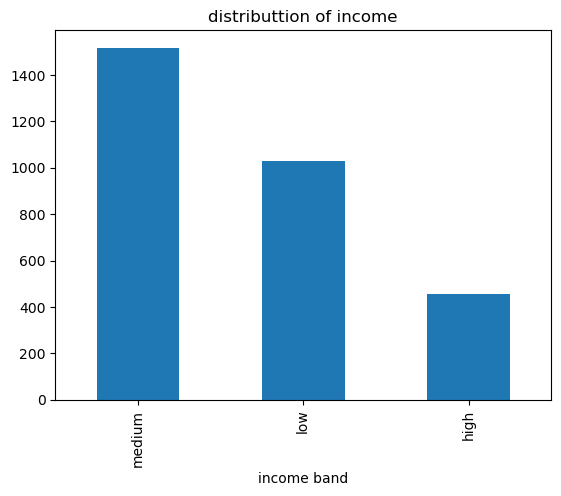

In [105]:
df["income band"].value_counts().plot(kind="bar" , title = "distributtion of income")

In [106]:
# feature enginering on occupation

In [107]:
import pandas as pd

def group_occupation(job):
    job = str(job).strip().lower()

    # IT & Software
    if any(x in job for x in [
        "software", "programmer", "developer",
        "database administrator", "systems administrator",
        "computer systems analyst", "help desk",
        "web developer", "information systems",
        "desktop support", "technical writer",
        "gis technical architect"
    ]):
        return "IT & Software"

    # Finance & Accounting
    elif any(x in job for x in [
        "accountant", "accounting", "financial",
        "actuary", "auditor", "tax accountant",
        "budget/accounting", "payment adjustment",
        "investment"
    ]):
        return "Finance & Accounting"

    # Healthcare & Social Care
    elif any(x in job for x in [
        "nurse", "health coach", "pharmacist",
        "therapist", "clinical", "dental hygienist",
        "speech pathologist", "social worker"
    ]):
        return "Healthcare & Social Care"

    # Science & Research
    elif any(x in job for x in [
        "geologist", "scientist", "biostatistician",
        "statistician", "research", "chemist",
        "environmental specialist", "environmental tech"
    ]):
        return "Science & Research"

    # Engineering & Safety
    elif any(x in job for x in [
        "engineer", "automation specialist",
        "safety technician", "quality engineer",
        "quality control"
    ]):
        return "Engineering & Safety"

    # HR & Recruitment
    elif any(x in job for x in [
        "human resources", "recruiter", "recruiting"
    ]):
        return "HR & Recruitment"

    # Sales & Marketing
    elif any(x in job for x in [
        "sales", "marketing", "media manager",
        "media planner", "account representative",
        "account executive", "sales associate"
    ]):
        return "Sales & Marketing"

    # Design & Creative
    elif any(x in job for x in [
        "designer", "editor", "circuit design"
    ]):
        return "Design & Creative"

    # Education
    elif any(x in job for x in [
        "teacher", "professor", "librarian"
    ]):
        return "Education"

    # Management
    elif any(x in job for x in [
        "manager", "vice president", "vp ",
        "general manager", "project manager",
        "junior executive", "assistant manager"
    ]):
        return "Management"

    # Administration & Legal
    elif any(x in job for x in [
        "administrative", "office assistant",
        "secretary", "paralegal", "legal assistant",
        "coordinator"
    ]):
        return "Administration & Legal"

    else:
        return "Other / Specialized"


df["Occupation Group"] = df["Occupation"].apply(group_occupation)

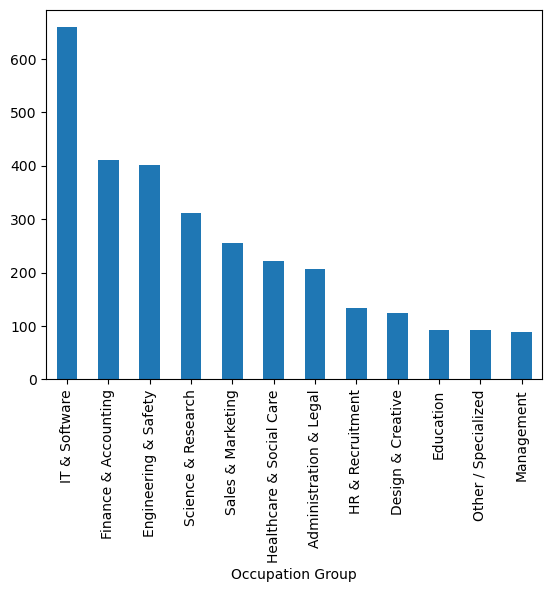

In [108]:
df["Occupation Group"].value_counts().plot(kind="bar")
plt.show()

In [109]:
#columns seprate 

In [110]:
df.columns

Index(['Client ID', 'Name', 'Age', 'Location ID', 'Joined Bank',
       'Banking Contact', 'Nationality', 'Occupation', 'Fee Structure',
       'Loyalty Classification', 'Estimated Income', 'Superannuation Savings',
       'Amount of Credit Cards', 'Credit Card Balance', 'Bank Loans',
       'Bank Deposits', 'Checking Accounts', 'Saving Accounts',
       'Foreign Currency Account', 'Business Lending', 'Properties Owned',
       'Risk Weighting', 'Gender', 'Investment Advisor',
       'Banking Relationship', 'income band', 'Occupation Group'],
      dtype='object')

In [111]:
categorical_cols = ["Nationality","Occupation Group","Fee Structure","Loyalty Classification","Gender","Investment Advisor","Banking Relationship","income band",'Risk Weighting','Properties Owned','Amount of Credit Cards']


In [112]:
df[categorical_cols]

,Nationality,Occupation Group,Fee Structure,Loyalty Classification,Gender,Investment Advisor,Banking Relationship,income band,Risk Weighting,Properties Owned,Amount of Credit Cards
0,American,Engineering & Safety,High,Jade,Male,Victor Dean,Retail,low,2,1,1
1,African,IT & Software,High,Jade,Male,Jeremy Porter,Institutional,medium,3,1,1
2,European,IT & Software,High,Gold,Female,Ernest Knight,Private Bank,medium,3,1,2
3,American,Science & Research,Mid,Silver,Male,Eric Shaw,Commercial,high,4,0,2
4,American,Education,Mid,Platinum,Female,Kevin Kim,Retail,medium,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...
2995,American,Finance & Accounting,High,Gold,Female,Eric Shaw,Private Bank,medium,3,1,1
2996,European,Administration & Legal,Mid,Gold,Female,Kevin Kim,Private Bank,low,2,1,1
2997,American,Science & Research,Low,Jade,Female,Victor Rogers,Private Bank,low,2,2,1
2998,European,HR & Recruitment,Mid,Jade,Female,Eugene Cunningham,Private Bank,medium,1,3,2


In [113]:
#univirate analysis

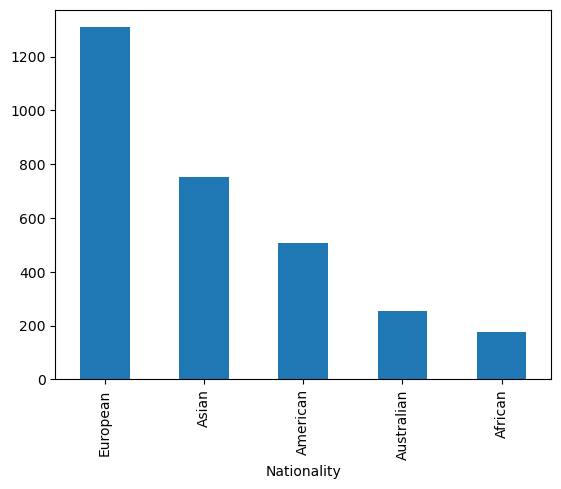

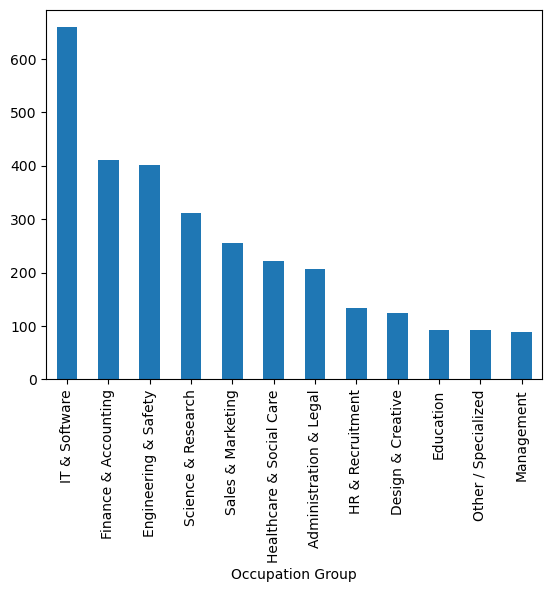

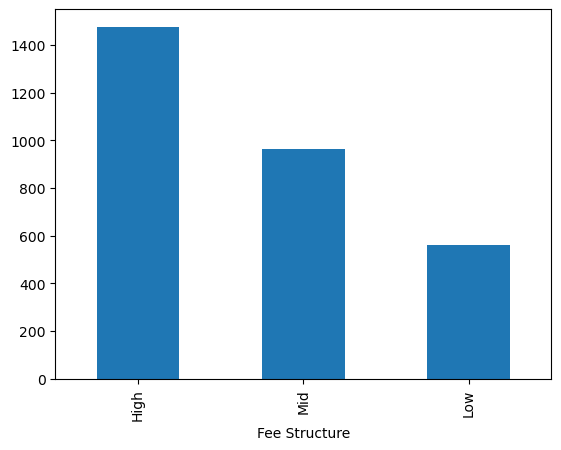

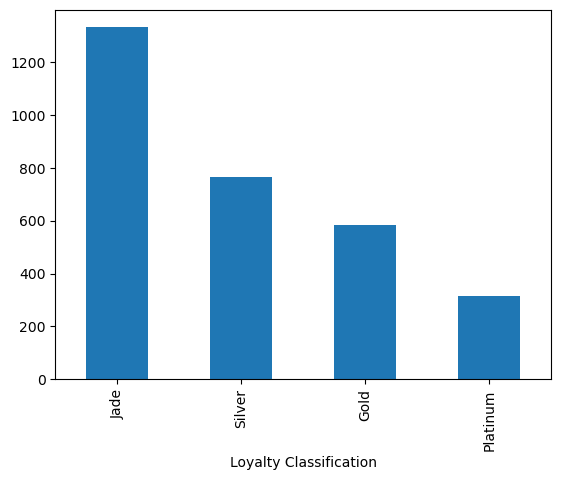

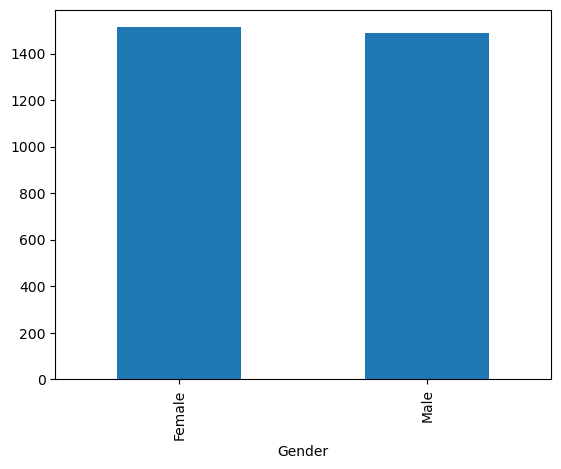

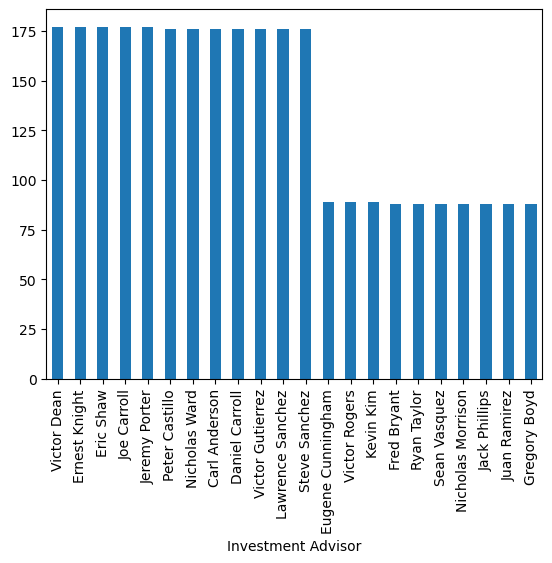

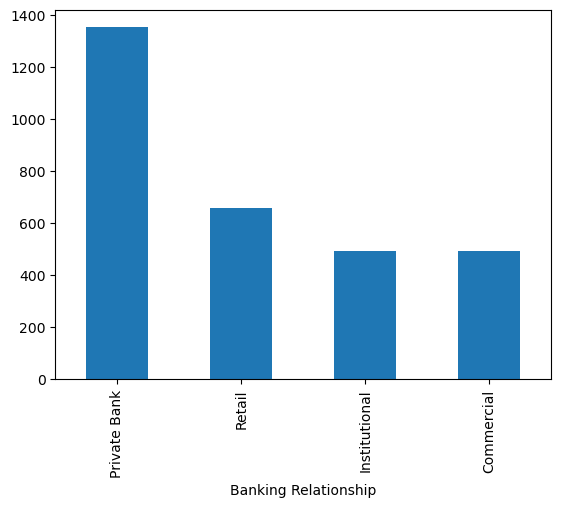

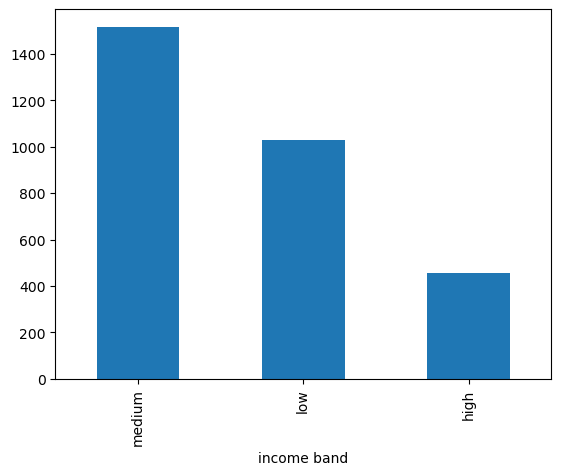

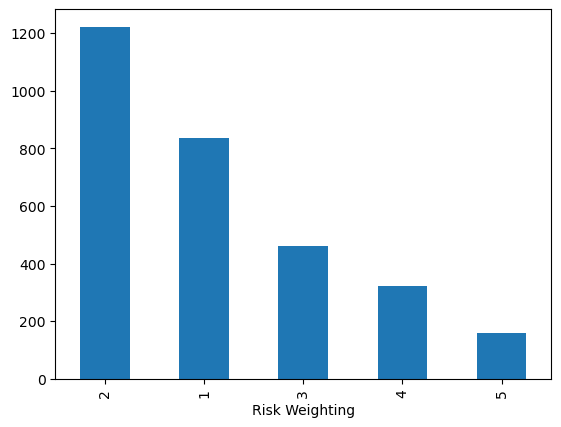

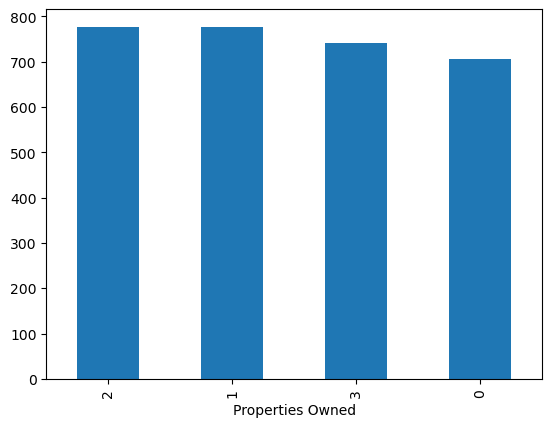

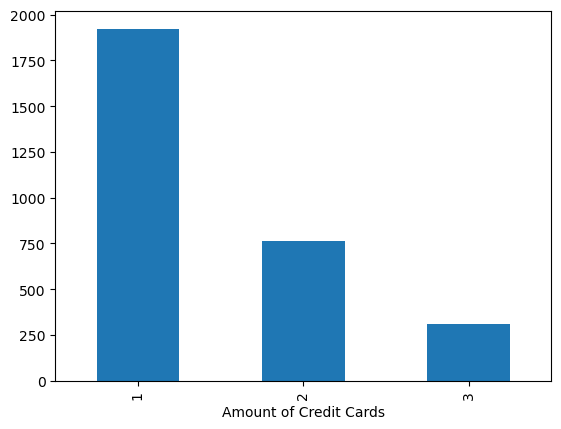

In [114]:
for i in categorical_cols:
    df[i].value_counts().plot(kind="bar")
    plt.show()

In [115]:
# bivarate anlysis 
# with gender

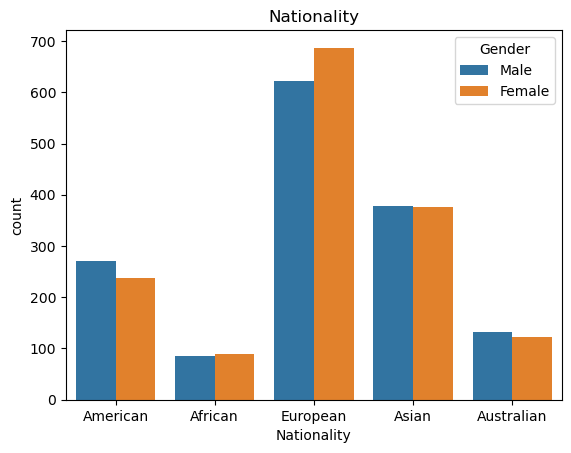

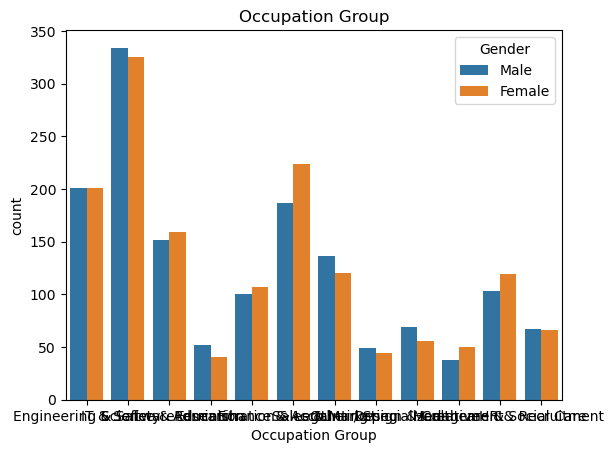

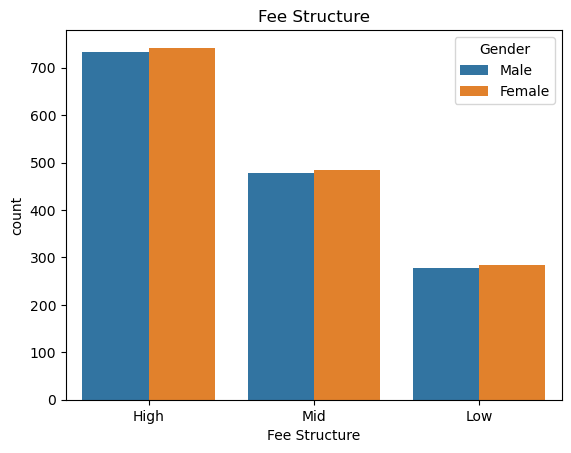

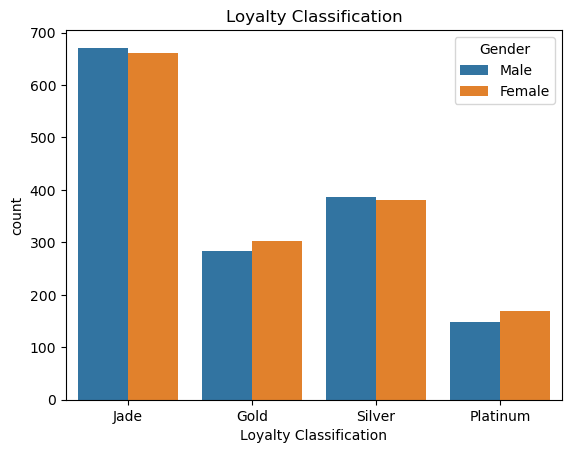

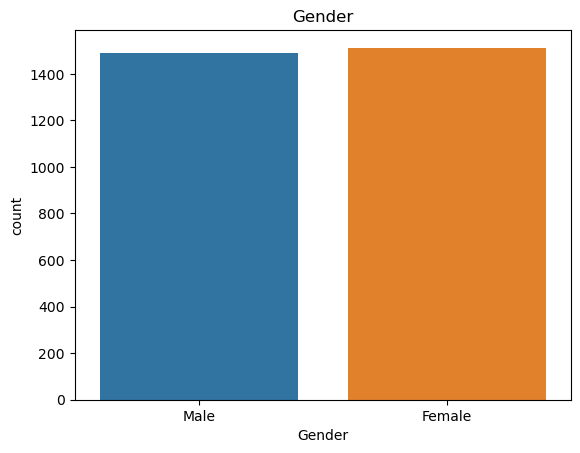

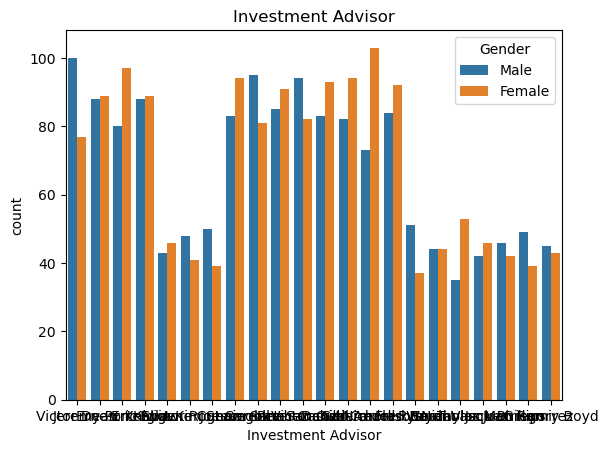

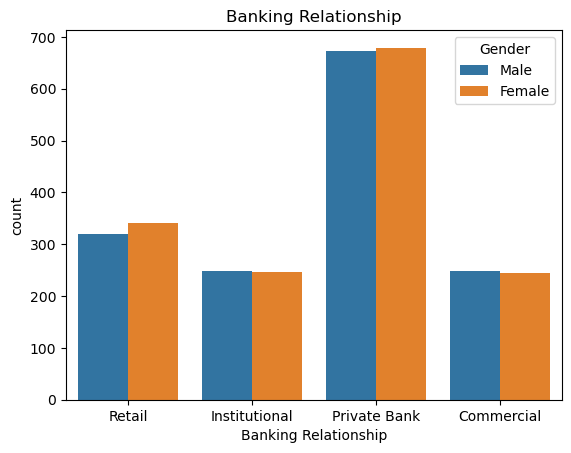

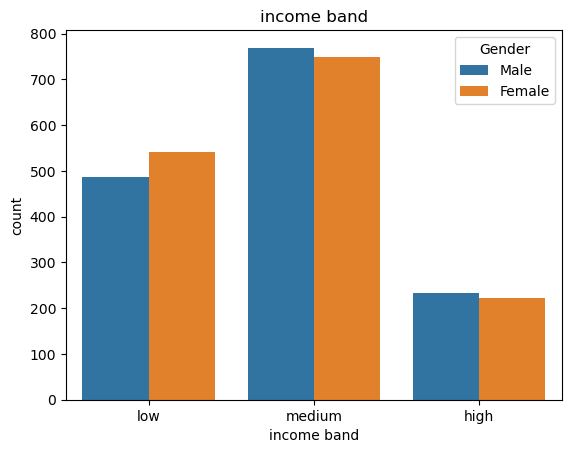

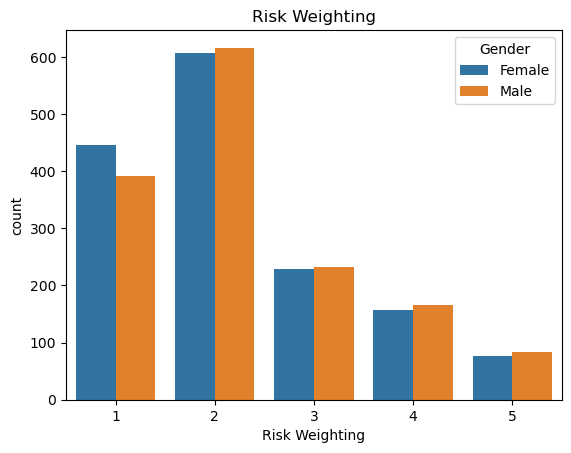

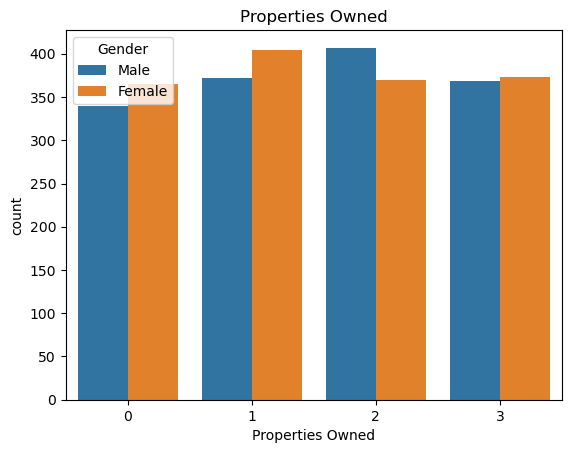

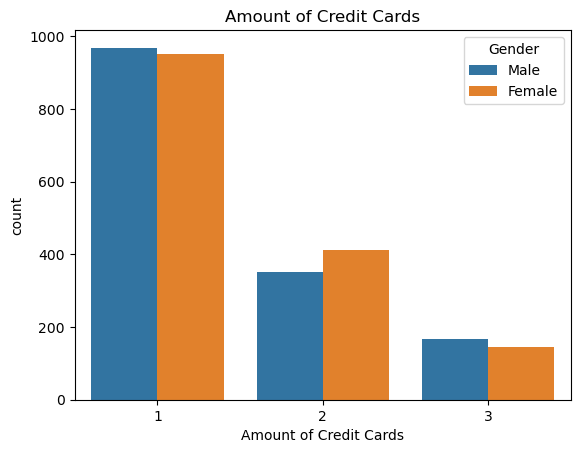

In [116]:
for i in categorical_cols:
    sns.countplot(data = df , x= i ,hue = "Gender")
    plt.title(i)
    plt.show()

In [117]:
df.columns

Index(['Client ID', 'Name', 'Age', 'Location ID', 'Joined Bank',
       'Banking Contact', 'Nationality', 'Occupation', 'Fee Structure',
       'Loyalty Classification', 'Estimated Income', 'Superannuation Savings',
       'Amount of Credit Cards', 'Credit Card Balance', 'Bank Loans',
       'Bank Deposits', 'Checking Accounts', 'Saving Accounts',
       'Foreign Currency Account', 'Business Lending', 'Properties Owned',
       'Risk Weighting', 'Gender', 'Investment Advisor',
       'Banking Relationship', 'income band', 'Occupation Group'],
      dtype='object')

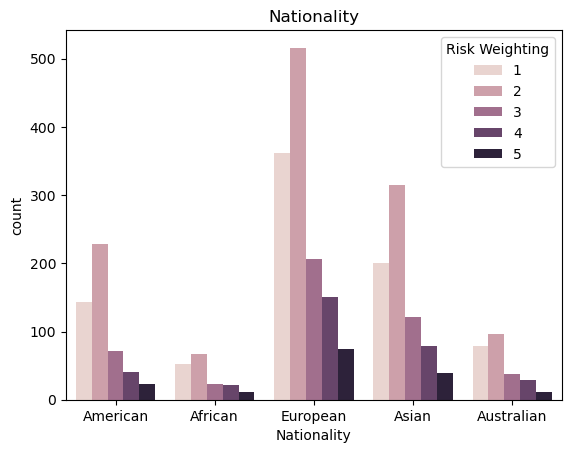

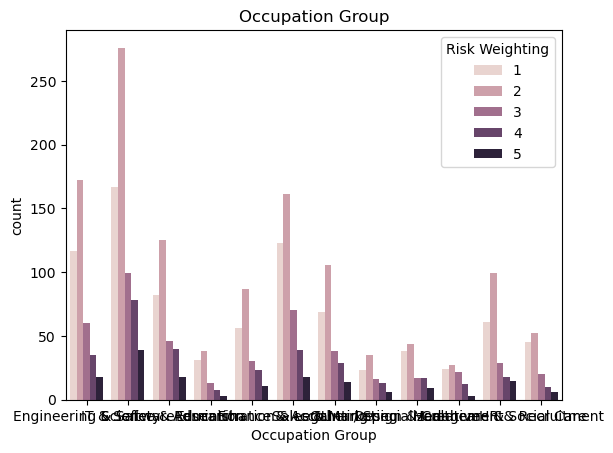

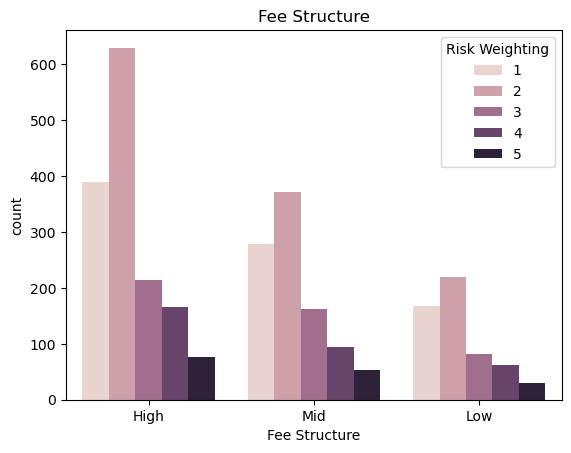

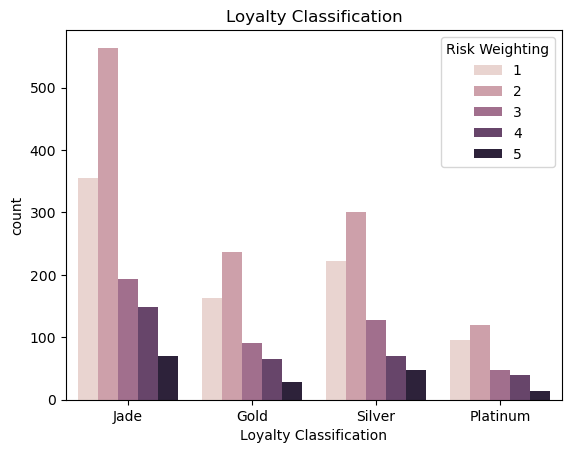

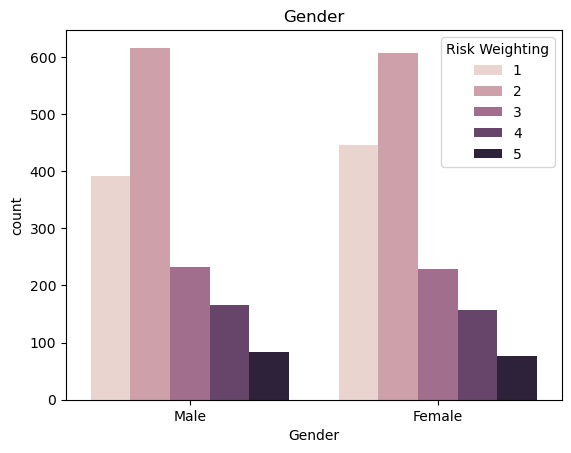

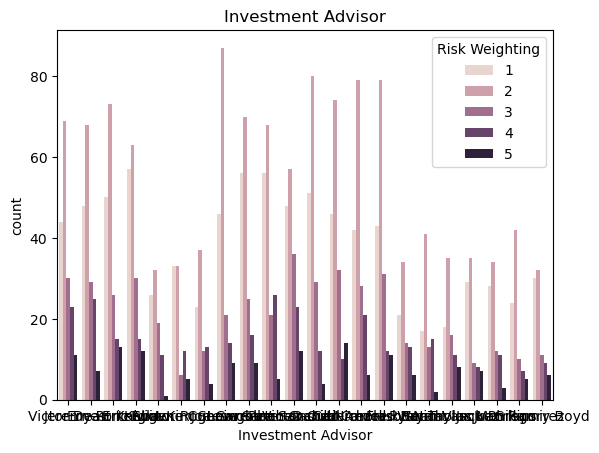

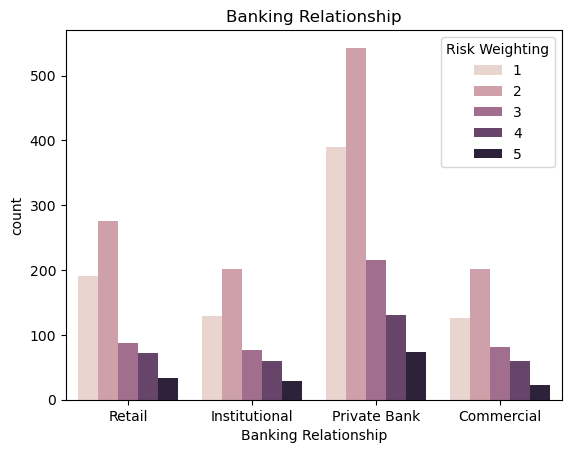

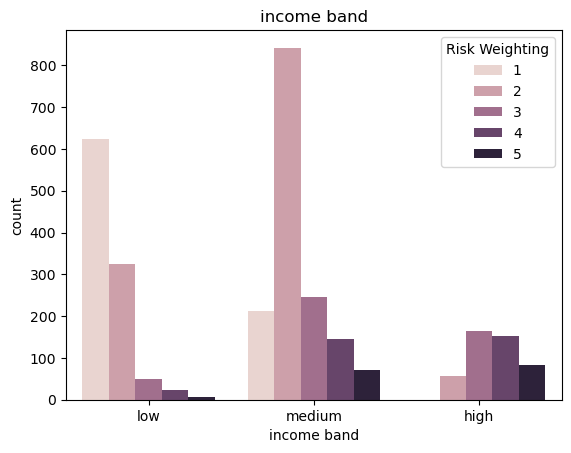

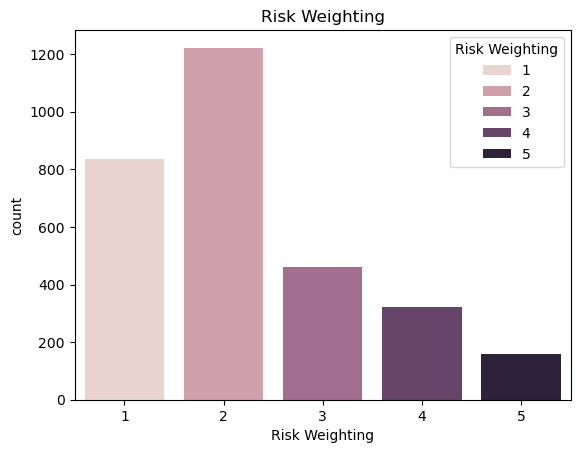

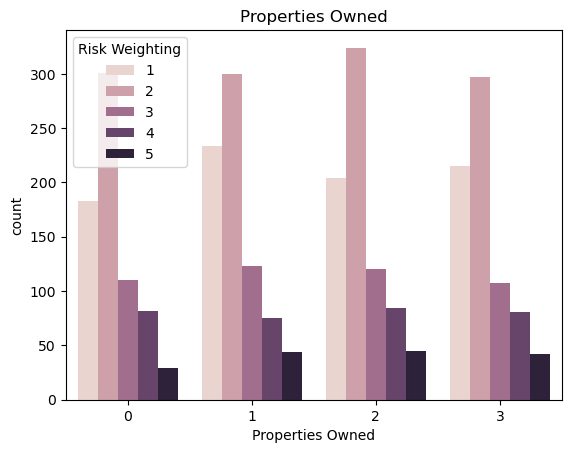

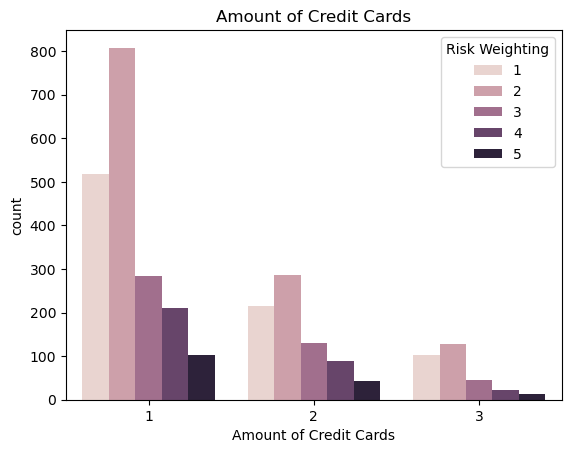

In [118]:
for i in categorical_cols:
    sns.countplot(data = df , x= i ,hue = "Risk Weighting")
    plt.title(i)
    plt.show()

In [119]:
# numerical distribution 

In [120]:
numarical_cols = ["Age","Estimated Income","Superannuation Savings","Credit Card Balance","Bank Loans","Bank Deposits","Checking Accounts","Saving Accounts","Foreign Currency Account","Business Lending"]

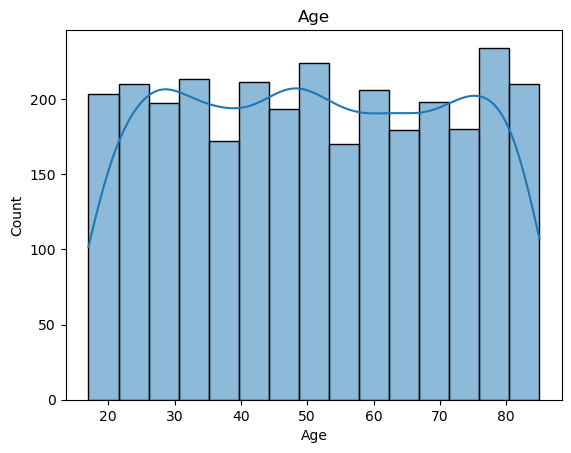

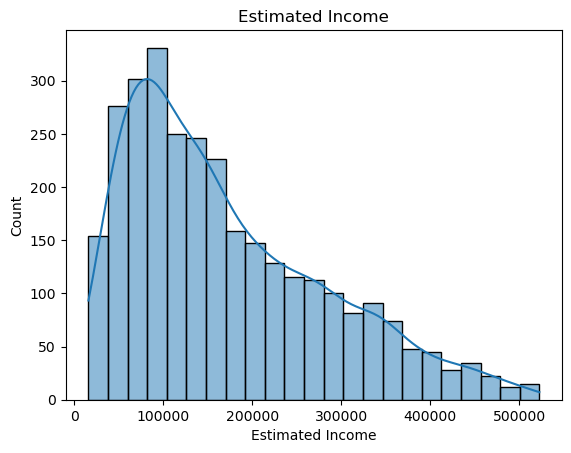

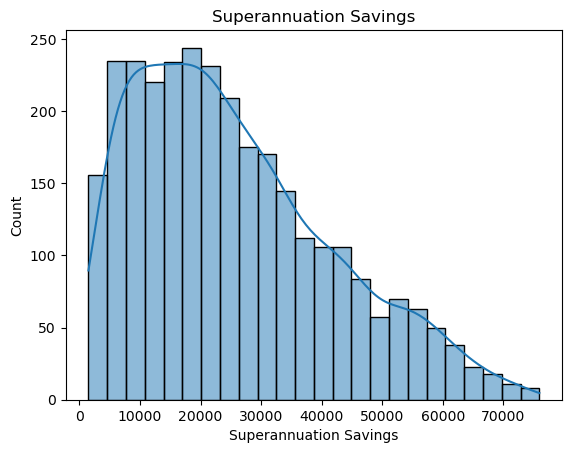

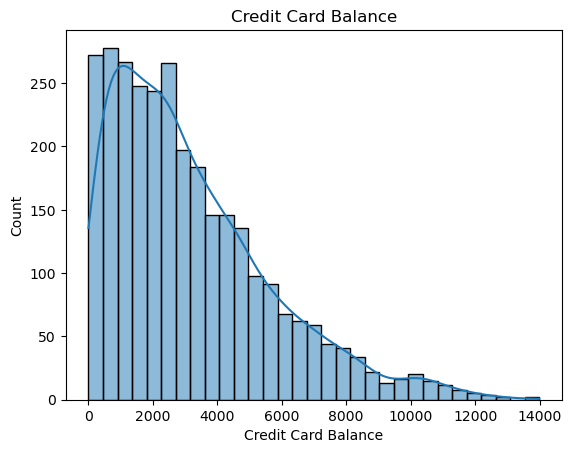

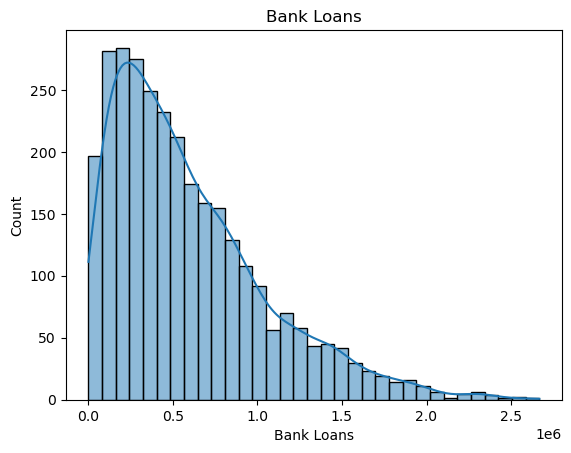

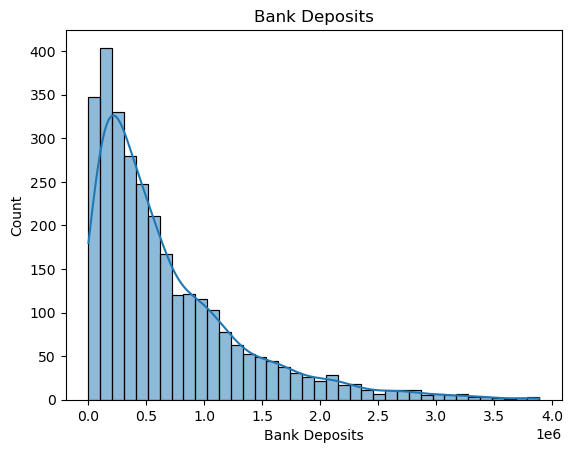

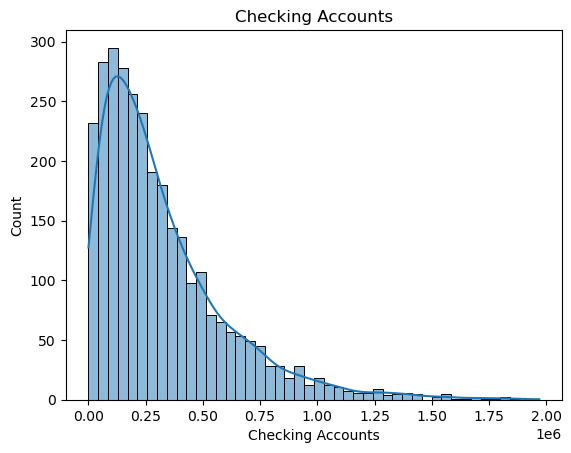

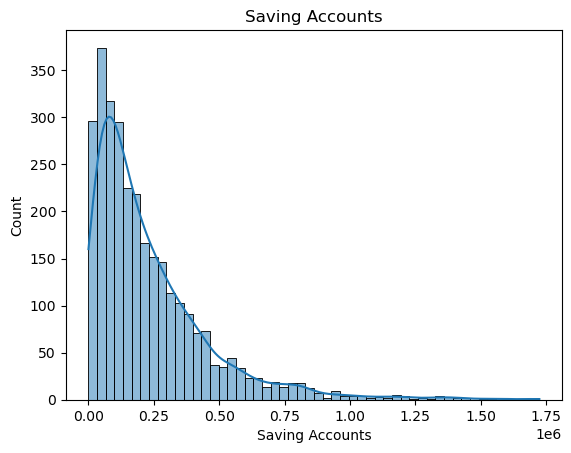

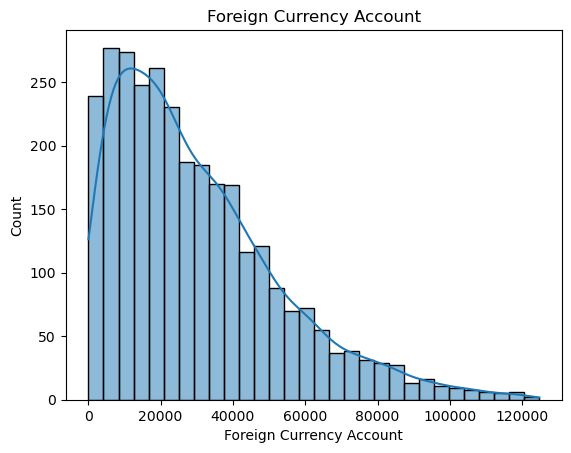

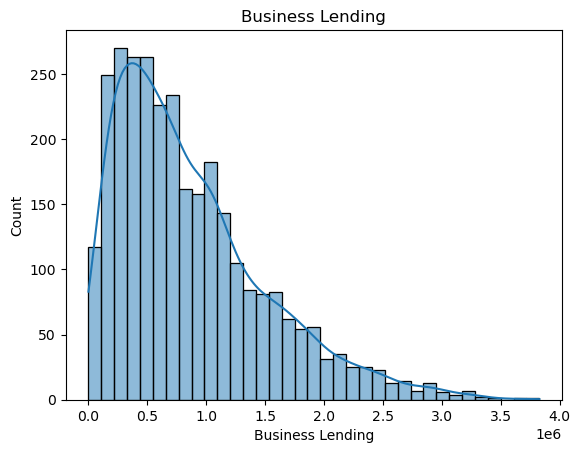

In [121]:
for i in numarical_cols:
    sns.histplot(df[i],kde = True )
    plt.title(i)
    plt.show()


In [122]:
# correlation matrix

In [123]:
corr_matrix=df[numarical_cols].corr()

<Axes: >

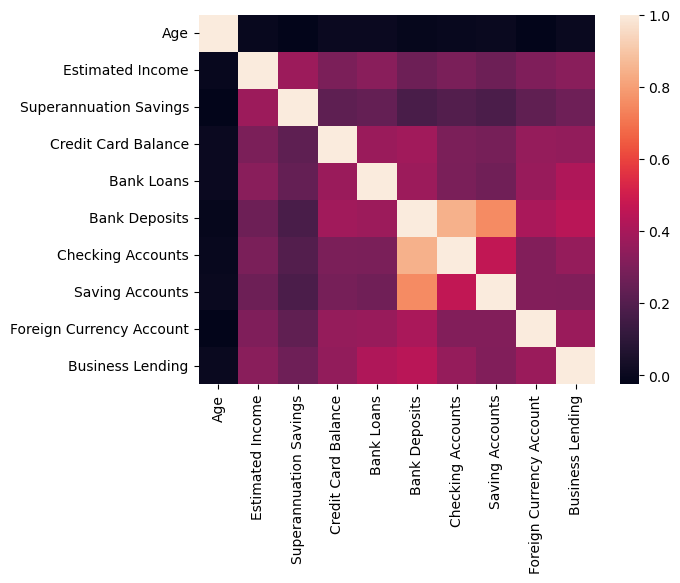

In [124]:
sns.heatmap(corr_matrix)

In [125]:
# outlier ditection

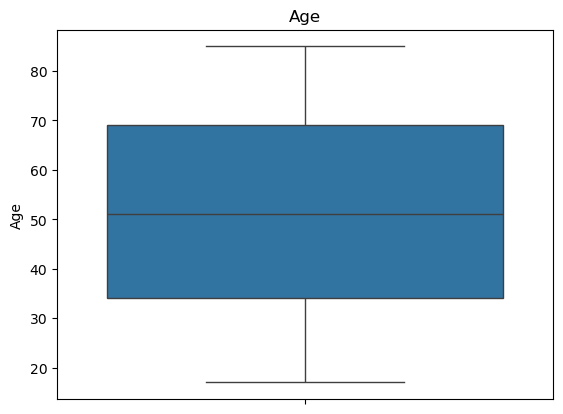

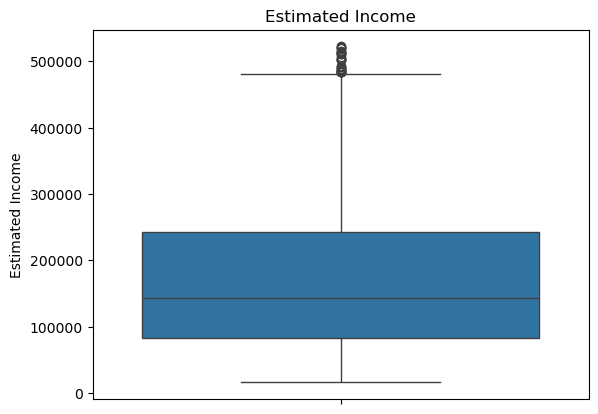

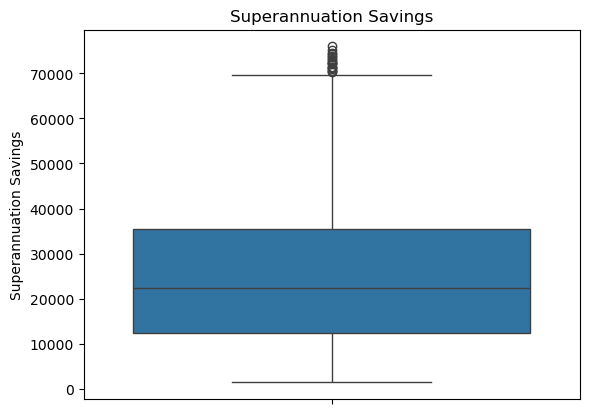

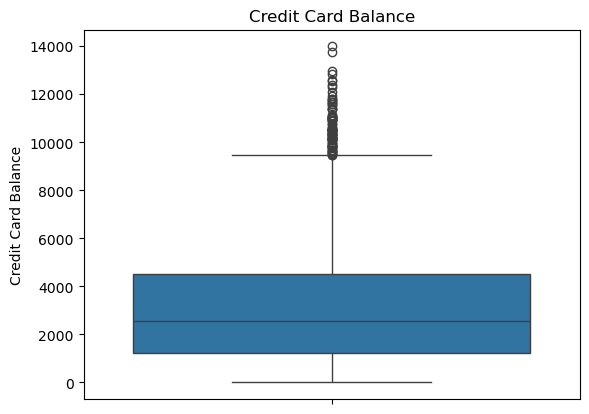

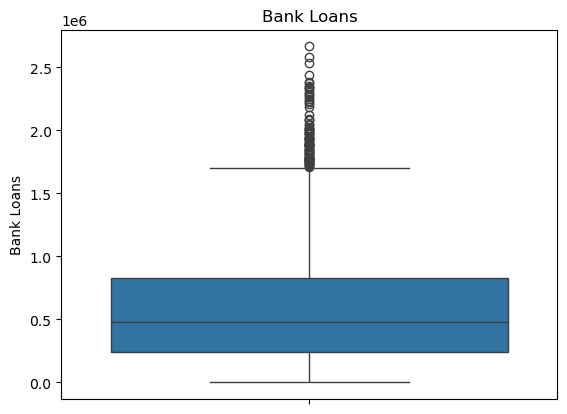

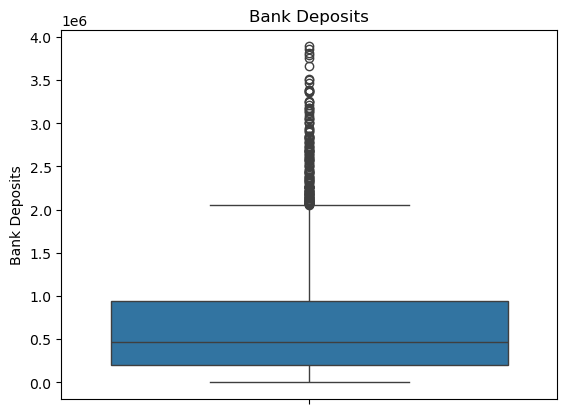

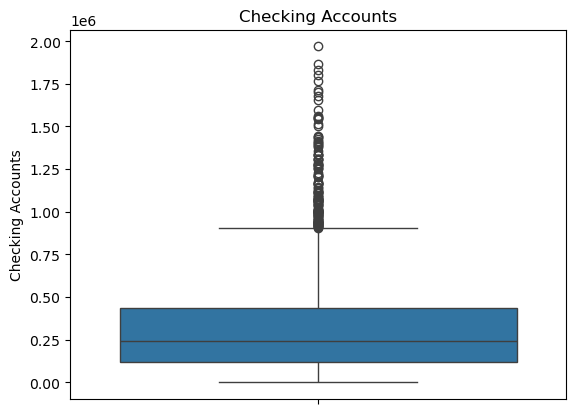

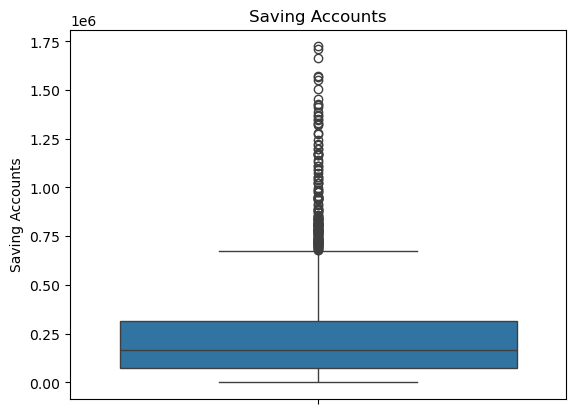

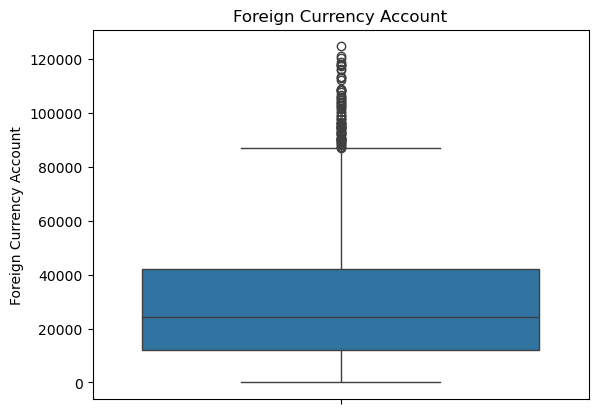

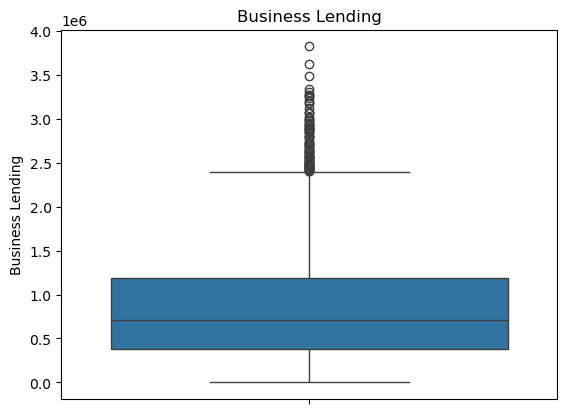

In [126]:
for i in numarical_cols:
    sns.boxplot(df[i])
    plt.title(i)
    plt.show()

In [127]:
q3=df["Age"].quantile(.75)
q1 = df["Age"].quantile(.25)
iqr = q3 - q1
iqr

np.float64(35.0)

In [128]:
mini = q1 - 1.5*iqr
maxi = q3 + 1.5*iqr


In [129]:
len(df[(df["Age"] < mini) | (df["Age"] > maxi)])

0

In [130]:
for i in numarical_cols:
    q3=df[i].quantile(.75)
    q1 = df[i].quantile(.25)
    iqr = q3 - q1
    mini = q1 - 1.5*iqr
    maxi = q3 + 1.5*iqr
    print(i , "  count of the outlier :- ",len(df[(df[i] < mini) | (df[i] > maxi)]))
    

Age   count of the outlier :-  0
Estimated Income   count of the outlier :-  26
Superannuation Savings   count of the outlier :-  19
Credit Card Balance   count of the outlier :-  85
Bank Loans   count of the outlier :-  85
Bank Deposits   count of the outlier :-  149
Checking Accounts   count of the outlier :-  138
Saving Accounts   count of the outlier :-  155
Foreign Currency Account   count of the outlier :-  79
Business Lending   count of the outlier :-  93


In [131]:
df.shape

(3000, 27)

In [132]:
# feature Selection

In [133]:
import scipy.stats as ss

In [134]:
df.columns

Index(['Client ID', 'Name', 'Age', 'Location ID', 'Joined Bank',
       'Banking Contact', 'Nationality', 'Occupation', 'Fee Structure',
       'Loyalty Classification', 'Estimated Income', 'Superannuation Savings',
       'Amount of Credit Cards', 'Credit Card Balance', 'Bank Loans',
       'Bank Deposits', 'Checking Accounts', 'Saving Accounts',
       'Foreign Currency Account', 'Business Lending', 'Properties Owned',
       'Risk Weighting', 'Gender', 'Investment Advisor',
       'Banking Relationship', 'income band', 'Occupation Group'],
      dtype='object')

In [135]:
# chi Square test

In [136]:
for i in categorical_cols:
    if i != "Risk Weighting":
        o=pd.crosstab(df["Risk Weighting"],df[i])
        s,p,d,e=ss.chi2_contingency(o)
        if p <= 0.05:
            print("Risk Weighting --"+i , p)
            print(f"{p:.10e}")

Risk Weighting --income band 0.0
0.0000000000e+00


In [137]:
# Anova test 

In [138]:
df["Risk Weighting"].value_counts()

Risk Weighting
2    1222
1     836
3     460
4     322
5     160
Name: count, dtype: int64

In [139]:
nk = []

In [140]:
for i in numarical_cols:
    g1 = df[df["Risk Weighting"]==1][i]
    g2 = df[df["Risk Weighting"]==2][i]
    g3 = df[df["Risk Weighting"]==3][i]
    g4 = df[df["Risk Weighting"]==4][i]
    g5 = df[df["Risk Weighting"]==5][i]

    s , p =ss.f_oneway(g1, g2 , g3 ,g4 , g5)
    if p < 0.05:
        print(i , p)
        nk.append(i)

Estimated Income 0.0
Superannuation Savings 3.665746421857426e-206
Credit Card Balance 2.948046616111052e-116
Bank Loans 1.0711164195378311e-133
Bank Deposits 7.276785448304216e-85
Checking Accounts 4.4399576735720676e-101
Saving Accounts 6.166902051040602e-87
Foreign Currency Account 2.664005549933213e-121
Business Lending 1.3648666961611834e-136


<Axes: >

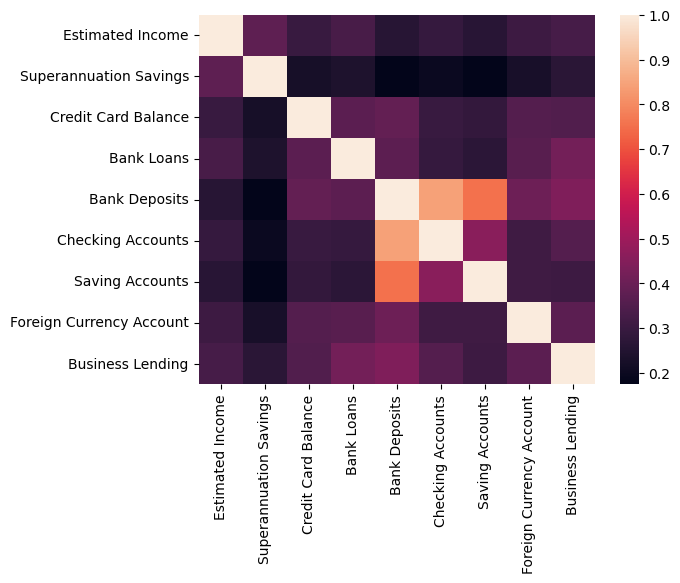

In [141]:
sns.heatmap(df[nk].corr())

In [45]:
df.to_csv("clinet.csv", index = False)